In [28]:
import pandas as pd
import numpy as np
import re
import joblib
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [29]:
train = pd.read_csv(
    "train_data.txt",
    sep=" ::: ",
    engine="python",
    names=["id", "title", "genre", "description"]
)

test = pd.read_csv(
    "test_data_solution.txt",
    sep=" ::: ",
    engine="python",
    names=["id", "title", "genre", "description"]
)

print(train.shape, test.shape)
print(train.head())

(54214, 4) (54200, 4)
   id                             title     genre  \
0   1      Oscar et la dame rose (2009)     drama   
1   2                      Cupid (1997)  thriller   
2   3  Young, Wild and Wonderful (1980)     adult   
3   4             The Secret Sin (1915)     drama   
4   5            The Unrecovered (2007)     drama   

                                         description  
0  Listening in to a conversation between his doc...  
1  A brother and sister with a past incestuous re...  
2  As the bus empties the students for their fiel...  
3  To help their unemployed father make ends meet...  
4  The film's title refers not only to the un-rec...  


id             0
title          0
genre          0
description    0
dtype: int64
genre
drama          13613
documentary    13096
comedy          7447
short           5073
horror          2204
thriller        1591
action          1315
western         1032
reality-tv       884
family           784
adventure        775
music            731
romance          672
sci-fi           647
adult            590
crime            505
animation        498
sport            432
talk-show        391
fantasy          323
mystery          319
musical          277
biography        265
history          243
game-show        194
news             181
war              132
Name: count, dtype: int64


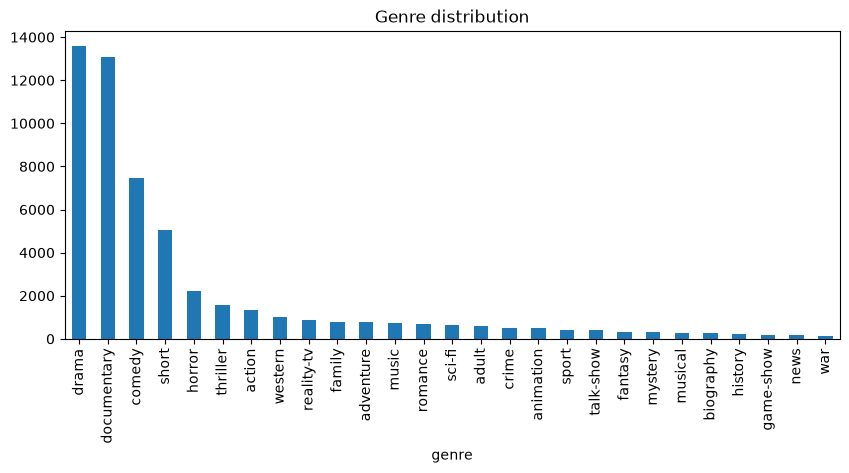

In [30]:
print(train.isnull().sum())          # missing values?
print(train["genre"].value_counts()) # class balance

train["genre"].value_counts().plot(kind="bar", figsize=(10, 4))
plt.title("Genre distribution")
plt.show()

In [31]:
def clean_text(text):
    text = str(text).lower()                 # lowercase
    text = re.sub(r"http\S+", " ", text)     # remove URLs
    text = re.sub(r"[^a-z\s]", " ", text)    # keep only letters
    text = re.sub(r"\s+", " ", text).strip() # collapse spaces
    return text

train["clean_desc"] = train["description"].apply(clean_text)
test["clean_desc"]  = test["description"].apply(clean_text)

In [32]:
train["text"] = train["title"].astype(str) + " " + train["clean_desc"]
test["text"]  = test["title"].astype(str)  + " " + test["clean_desc"]

In [33]:
X_train, y_train = train["text"], train["genre"]
X_test,  y_test  = test["text"],  test["genre"]

In [34]:
tfidf = TfidfVectorizer(
    stop_words="english",
    max_features=50000,
    ngram_range=(1, 2),   # single words and word pairs
    sublinear_tf=True
)

X_train_tfidf = tfidf.fit_transform(X_train)  # learn vocabulary on train only
X_test_tfidf  = tfidf.transform(X_test)       # only transform test

In [35]:
models = {
    "Naive Bayes": MultinomialNB(alpha=0.1),
    "Logistic Regression": LogisticRegression(max_iter=1000, C=10),
    "Linear SVM": LinearSVC(C=1.0)
}

results = {}
for name, model in models.items():
    model.fit(X_train_tfidf, y_train)
    preds = model.predict(X_test_tfidf)
    acc = accuracy_score(y_test, preds)
    results[name] = acc
    print(f"{name}: {acc:.4f}")

Naive Bayes: 0.5717
Logistic Regression: 0.6052
Linear SVM: 0.6001


Best model: Logistic Regression
              precision    recall  f1-score   support

      action       0.49      0.38      0.43      1314
       adult       0.72      0.40      0.52       590
   adventure       0.58      0.24      0.33       775
   animation       0.52      0.14      0.22       498
   biography       0.00      0.00      0.00       264
      comedy       0.56      0.61      0.58      7446
       crime       0.32      0.08      0.13       505
 documentary       0.71      0.83      0.76     13096
       drama       0.58      0.75      0.65     13612
      family       0.50      0.17      0.26       783
     fantasy       0.44      0.11      0.18       322
   game-show       0.85      0.59      0.70       193
     history       0.38      0.02      0.05       243
      horror       0.68      0.63      0.66      2204
       music       0.66      0.52      0.58       731
     musical       0.38      0.08      0.13       276
     mystery       0.37      0.05      0.08      

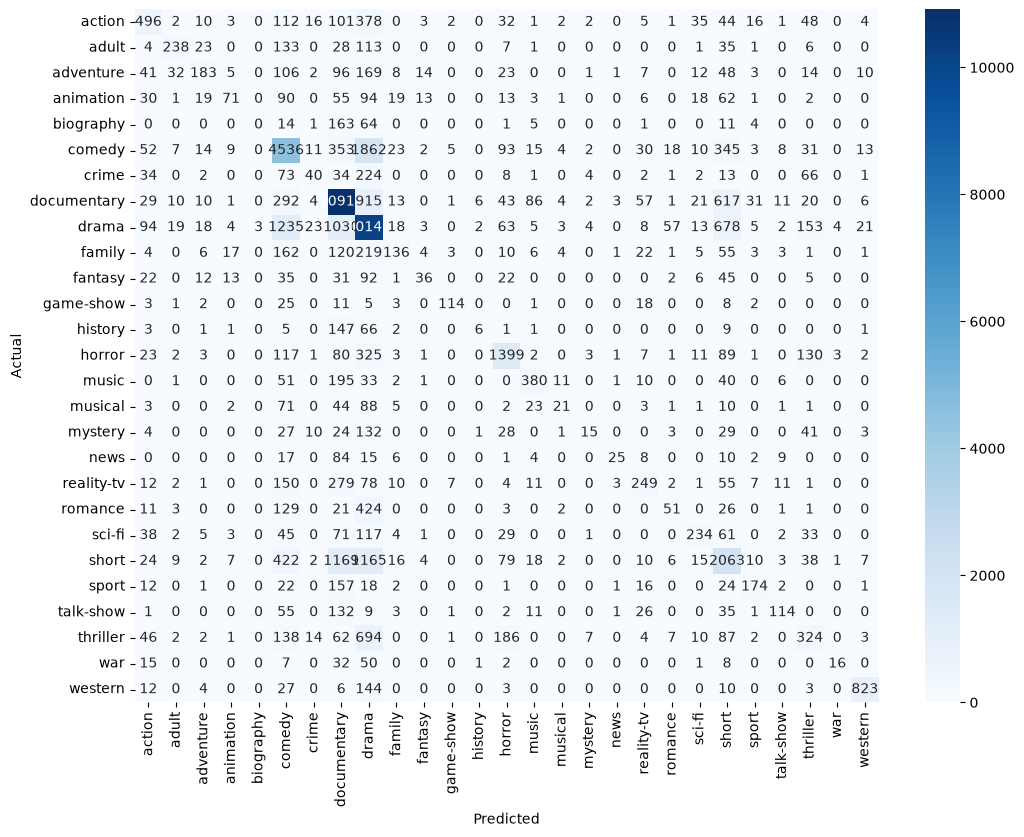

In [36]:
best_name = max(results, key=results.get)
best_model = models[best_name]
print("Best model:", best_name)

y_pred = best_model.predict(X_test_tfidf)
print(classification_report(y_test, y_pred))

# Confusion matrix
labels = sorted(y_train.unique())
cm = confusion_matrix(y_test, y_pred, labels=labels)
plt.figure(figsize=(12, 9))
sns.heatmap(cm, annot=True, fmt="d", xticklabels=labels, yticklabels=labels, cmap="Blues")
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.show()

In [37]:
def predict_genre(plot, title=""):
    text = clean_text(title) + " " + clean_text(plot)
    vec = tfidf.transform([text])
    return best_model.predict(vec)[0]

print(predict_genre("A group of astronauts travel through a wormhole to save humanity."))
print(predict_genre("A detective investigates a series of brutal murders in a small town."))

sci-fi
thriller


In [38]:
joblib.dump(best_model, "genre_model.pkl")
joblib.dump(tfidf, "tfidf_vectorizer.pkl")

# Later:
model = joblib.load("genre_model.pkl")
vectorizer = joblib.load("tfidf_vectorizer.pkl")